# Read Data and Its Paths

In [12]:
from pathlib import Path

DATA_DIR = Path("episode_2")

# Images (sorted by filename, which starts with a frame index and timestamp).
# Files starting with "._" are macOS metadata copies, not real images, so skip them.
def list_images(folder):
    return sorted(p for p in folder.glob("*.jpg") if not p.name.startswith("._"))

rgb_paths = list_images(DATA_DIR / "images" / "rgb")
thermal_paths = list_images(DATA_DIR / "images" / "thermal")

# Sensor logs
imu_log_path = DATA_DIR / "imu_log.csv"
gnss_log_path = DATA_DIR / "gnss_log.csv"
camera_log_path = DATA_DIR / "camera_log.csv"

print(f"RGB images:     {len(rgb_paths)}")
print(f"Thermal images: {len(thermal_paths)}")
print(f"IMU log:        {imu_log_path} (exists: {imu_log_path.exists()})")
print(f"GNSS log:       {gnss_log_path} (exists: {gnss_log_path.exists()})")
print(f"Camera log:     {camera_log_path} (exists: {camera_log_path.exists()})")

RGB images:     5742
Thermal images: 5742
IMU log:        episode_2/imu_log.csv (exists: True)
GNSS log:       episode_2/gnss_log.csv (exists: True)
Camera log:     episode_2/camera_log.csv (exists: True)


# Data Analysis

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True

NS = 1e9  # nanoseconds per second

# ---- Load the three logs --------------------------------------------------
imu = pd.read_csv(imu_log_path)
gnss = pd.read_csv(gnss_log_path)
cam = pd.read_csv(camera_log_path)

# Every sensor has its own name for the timestamp column. Give them all the same name
# ("t_ns") so the later steps can treat them identically.
imu = imu.rename(columns={"timestamp_ns": "t_ns"})
gnss = gnss.rename(columns={"timestamp_ns": "t_ns"})
cam = cam.rename(columns={"image_stamp_ns": "t_ns"})

print("Rows loaded -> IMU:", len(imu), "| GNSS:", len(gnss), "| camera:", len(cam))

Rows loaded -> IMU: 74687 | GNSS: 2989 | camera: 5742


In [14]:
# ---- Drop columns that carry no information --------------------------------
# A column with a single unique value (e.g. all covariances = 0, frame_id = "imu_link")
# tells us nothing, so remove it.
def drop_constant_columns(df, name):
    constant = [c for c in df.columns if df[c].nunique() <= 1]
    print(f"{name}: dropping {len(constant)} constant columns")
    return df.drop(columns=constant)

imu = drop_constant_columns(imu, "IMU")
gnss = drop_constant_columns(gnss, "GNSS")
cam = drop_constant_columns(cam, "camera")

print("\nIMU columns :", list(imu.columns))
print("GNSS columns:", list(gnss.columns))

IMU: dropping 28 constant columns
GNSS: dropping 9 constant columns
camera: dropping 1 constant columns

IMU columns : ['t_ns', 'timestamp_utc', 'orientation_x', 'orientation_y', 'orientation_z', 'orientation_w', 'angular_velocity_x', 'angular_velocity_y', 'angular_velocity_z', 'linear_acceleration_x', 'linear_acceleration_y', 'linear_acceleration_z']
GNSS columns: ['t_ns', 'timestamp_utc', 'status', 'latitude', 'longitude', 'altitude', 'position_covariance_0', 'position_covariance_4', 'position_covariance_8']


IMU     rows= 74687  span=  979.3 s  median dt=  10.0 ms  backwards steps=3  gaps>50 ms=2
GNSS    rows=  2989  span=  979.0 s  median dt= 250.0 ms  backwards steps=0  gaps>1000 ms=1
camera  rows=  5742  span=  979.2 s  median dt= 199.3 ms  backwards steps=0  gaps>500 ms=0


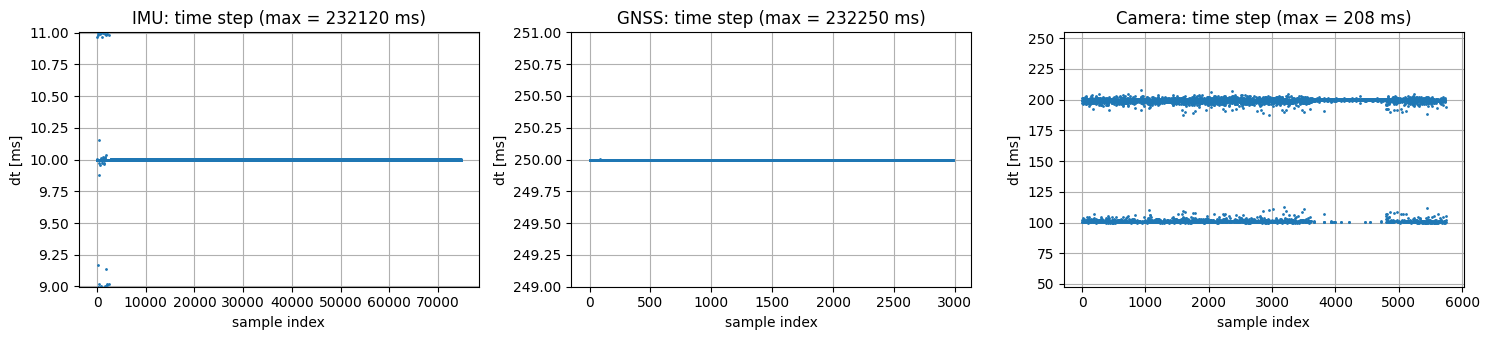

In [15]:
# ---- Check the timestamps of each sensor ------------------------------------
# For a healthy sensor every time step (dt = t[i+1] - t[i]) is positive and close to
# the nominal period. We look for:
#   * backwards steps (dt <= 0): samples that are out of order
#   * large gaps: samples that are missing
def timestamp_report(df, name, gap_ms):
    dt_ms = np.diff(df["t_ns"].values) / 1e6
    span_s = (df["t_ns"].iloc[-1] - df["t_ns"].iloc[0]) / NS
    print(f"{name:7s} rows={len(df):6d}  span={span_s:7.1f} s  "
          f"median dt={np.median(dt_ms):6.1f} ms  "
          f"backwards steps={np.sum(dt_ms <= 0)}  gaps>{gap_ms} ms={np.sum(dt_ms > gap_ms)}")
    return dt_ms

imu_dt = timestamp_report(imu, "IMU", gap_ms=50)
gnss_dt = timestamp_report(gnss, "GNSS", gap_ms=1000)
cam_dt = timestamp_report(cam, "camera", gap_ms=500)

# Plot dt for each sensor. The y-axis is clipped so normal jitter stays visible;
# the huge gaps are annotated in the title instead.
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, dt, name in zip(axes, [imu_dt, gnss_dt, cam_dt], ["IMU", "GNSS", "Camera"]):
    ax.plot(dt, ".", markersize=2)
    lo, hi = np.percentile(dt, [1, 99])
    margin = 0.5 * (hi - lo) + 1
    ax.set_ylim(lo - margin, hi + margin)
    ax.set_title(f"{name}: time step (max = {dt.max():.0f} ms)")
    ax.set_xlabel("sample index")
    ax.set_ylabel("dt [ms]")
plt.tight_layout()
plt.show()

### What the time-step plots show

Each dot is the time between one sample and the next (`dt`). A healthy sensor makes a flat line.

- **IMU (left):** nearly all dots sit on 10 ms, so the IMU runs at 100 Hz. The scattered dots at the far left (first ~2,500 samples) are timestamp glitches: some samples are only a few ms apart and a few jump backwards. The plot is zoomed in, so the huge 232 s gap in the title is not visible here.
- **GNSS (middle):** a perfectly flat line at 250 ms, so 4 Hz. The only problem is the same 232 s gap.
- **Camera (right):** two bands, one near 100 ms and one near 200 ms. The camera is not at a fixed rate. Some frames come 0.1 s apart and others 0.2 s apart, and the average is about 170 ms. There are no gaps, so every frame is accounted for.

**What it means:** the IMU and GNSS are steady except for the glitches at the start and the one long gap. The camera timing is uneven, so later we must interpolate the IMU and GNSS to each frame's own timestamp. We can't assume one frame every 0.2 s.

In [16]:
# ---- Fix the ordering and build a common time axis ---------------------------
# Sort every table by timestamp and remove exact duplicate timestamps, so that
# time always moves forward.
def sort_by_time(df):
    return df.sort_values("t_ns", kind="stable").drop_duplicates("t_ns").reset_index(drop=True)

imu = sort_by_time(imu)
gnss = sort_by_time(gnss)
cam = sort_by_time(cam)

# All three logs use the same clock, so one shared zero point works for all of them:
# the first IMU sample. "t_s" is then time in seconds since the start of the recording.
T0_NS = imu["t_ns"].iloc[0]
for df in (imu, gnss, cam):
    df["t_s"] = (df["t_ns"] - T0_NS) / NS

# GNSS: status -1 means "no fix". Those rows have a meaningless position and a
# covariance of ~1e13, so mark them instead of deleting them.
gnss["has_fix"] = gnss["status"] >= 0
print(f"GNSS rows with a fix: {gnss['has_fix'].sum()} / {len(gnss)}")

# The IMU has a long hole in its timestamps (see the plot above). Find where it is.
imu_gap = imu["t_s"].diff()
big = imu_gap[imu_gap > 1.0]
for idx, gap in big.items():
    print(f"IMU gap: no samples for {gap:.1f} s, from t={imu['t_s'].iloc[idx-1]:.1f} s "
          f"to t={imu['t_s'].iloc[idx]:.1f} s")

GNSS rows with a fix: 2900 / 2989
IMU gap: no samples for 232.1 s, from t=590.9 s to t=823.0 s


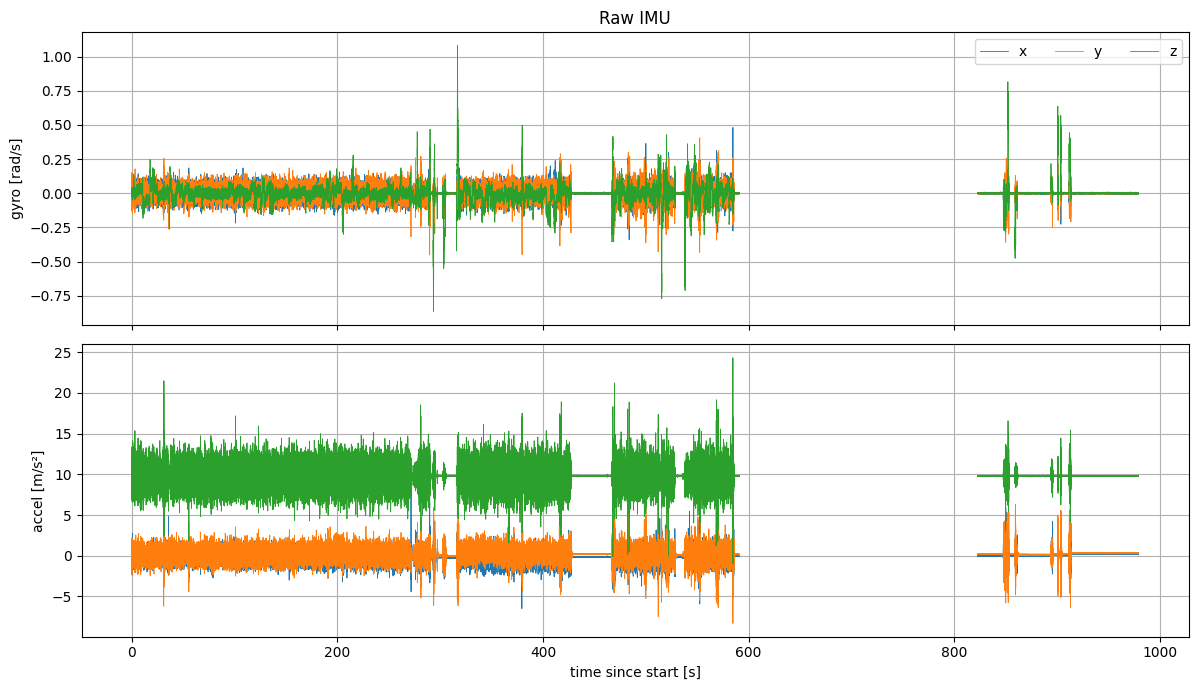

|accel|: median = 9.80 m/s²  (gravity = 9.81)


In [17]:
# ---- Plot the raw IMU signals ------------------------------------------------
# Gyroscope (rotation rate) and accelerometer (specific force) on three axes each.
# NaN is inserted into the gap so the line is not drawn straight across it.
def with_gap_breaks(df, max_gap_s=1.0):
    out = df.copy()
    out.loc[out["t_s"].diff() > max_gap_s, :] = np.nan
    return out

# (the line above blanks the *first row after* each gap, which breaks the line there)
imu_plot = with_gap_breaks(imu)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for axis in "xyz":
    axes[0].plot(imu_plot["t_s"], imu_plot[f"angular_velocity_{axis}"], lw=0.6, label=axis)
    axes[1].plot(imu_plot["t_s"], imu_plot[f"linear_acceleration_{axis}"], lw=0.6, label=axis)
axes[0].set_ylabel("gyro [rad/s]")
axes[1].set_ylabel("accel [m/s²]")
axes[1].set_xlabel("time since start [s]")
axes[0].set_title("Raw IMU")
axes[0].legend(ncol=3)
plt.tight_layout()
plt.show()

# Quick physical sanity check: when the vehicle is not accelerating hard, the length of
# the accel vector should be about 9.81 m/s² (gravity).
accel_norm = np.sqrt((imu[[f"linear_acceleration_{a}" for a in "xyz"]] ** 2).sum(axis=1))
print(f"|accel|: median = {accel_norm.median():.2f} m/s²  (gravity = 9.81)")

### What the raw IMU plot shows

Top: the gyroscope, which measures how fast the sensor is rotating (rad/s). Bottom: the accelerometer, which measures acceleration including gravity (m/s²). The colors are the x, y and z axes.

- **Noisy stretches:** while the vehicle drives (0–430 s, 465–590 s and short bursts after 823 s) both signals are fuzzy. The gyro swings by about ±0.15 rad/s with occasional spikes up to ±0.75 rad/s. The z accelerometer (green) swings around 10 m/s² by about ±5 m/s². This is mostly vibration, bumps and motor noise, not real motion.
- **Flat stretches:** when the vehicle stops, for example around 430–465 s and 920–980 s, the lines collapse to thin flat lines. The gyro sits near 0 and z accel sits near 9.8 m/s², which is gravity. These calm stretches are what we will use to measure the sensor's own noise and bias.
- **The blank gap:** between about 591 s and 823 s there is no IMU data (the 232 s hole). The line is deliberately broken there instead of drawn across it.

**What it means:** the signal is large compared with the sensor's own noise whenever the vehicle moves, so noise must be measured only on the flat, stationary parts. The strong vibration also tells us the IMU is mounted rigidly on a vibrating platform. That is useful to know for filtering later.

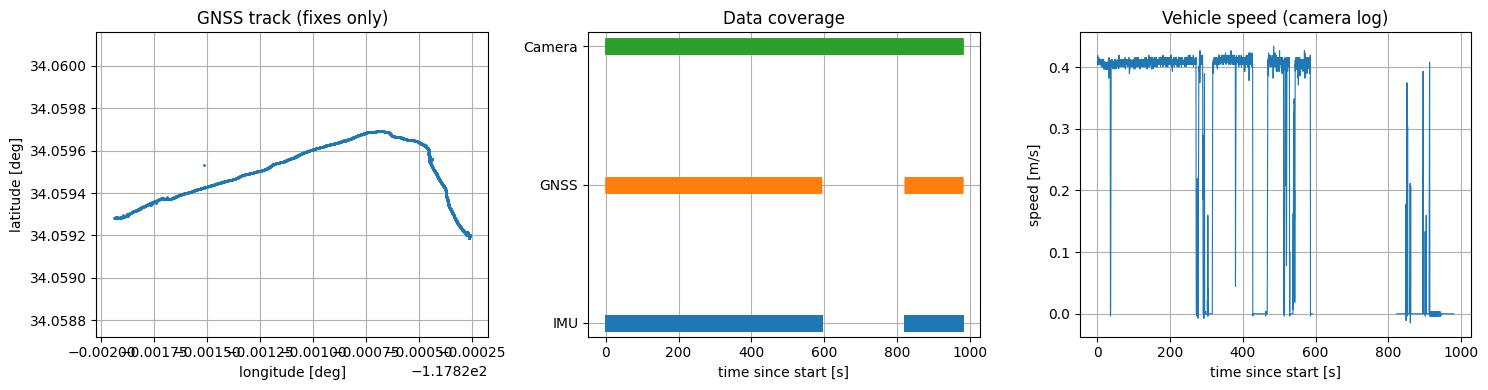

In [18]:
# ---- Plot the GNSS track and the camera timing --------------------------------
fix = gnss[gnss["has_fix"]]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1) Where the vehicle went (longitude on x, latitude on y)
axes[0].plot(fix["longitude"], fix["latitude"], ".", markersize=2)
axes[0].set_title("GNSS track (fixes only)")
axes[0].set_xlabel("longitude [deg]")
axes[0].set_ylabel("latitude [deg]")
axes[0].set_aspect("equal", adjustable="datalim")

# 2) When each sensor was recording. A vertical bar = one sample; empty stretches = no data.
for row, (df, name) in enumerate([(imu, "IMU"), (gnss, "GNSS"), (cam, "Camera")]):
    axes[1].plot(df["t_s"], np.full(len(df), row), "|", markersize=12)
axes[1].set_yticks([0, 1, 2])
axes[1].set_yticklabels(["IMU", "GNSS", "Camera"])
axes[1].set_xlabel("time since start [s]")
axes[1].set_title("Data coverage")

# 3) Camera speed over time, to see when the vehicle is moving or stopped
axes[2].plot(cam["t_s"], cam["speed_mps"], lw=0.8)
axes[2].set_title("Vehicle speed (camera log)")
axes[2].set_xlabel("time since start [s]")
axes[2].set_ylabel("speed [m/s]")

plt.tight_layout()
plt.show()

### What the GNSS, coverage and speed plots show

- **GNSS track (left):** the path the vehicle drove, as longitude and latitude from the satellite receiver. It is a smooth curve about 150 m long, running left to right and then turning downward. The one dot off the line near the middle is a bad position reading. Only rows with a fix are drawn.
- **Data coverage (middle):** each bar shows when a sensor was recording. The camera (green) runs the whole time. The GNSS and IMU bars both stop at about 591 s and resume at about 823 s. This is the interruption you described: the camera kept collecting while the other sensors stalled.
- **Vehicle speed (right):** the speed from the camera log. The vehicle cruises at about 0.4 m/s (slow walking pace) and drops to 0 each time it stops. Those drops line up with the flat, quiet parts of the IMU plot. From about 590 s to 845 s the speed is 0, so the vehicle was parked while the IMU and GNSS were down.

**What it means:**
- The ~1,176 camera frames inside the gap show a stationary vehicle, so little is lost by having no IMU or GNSS there.
- The speed trace gives a ready way to find stationary stretches for the noise analysis in the next step.
- The vehicle is slow, so motion between frames is small.

# IMU Noise Analysis

Every IMU is a little bit wrong. Even held perfectly still, its numbers jiggle (**noise**) and the gyroscope does not read exactly zero (**bias**). Later steps (VIO, filtering) need to know how big these errors are.

The plan, in four small steps:
1. Find a time when the vehicle was standing still.
2. Measure the jiggle and the offset there.
3. Compare with the jiggle while driving, to see how small the sensor's own noise is.
4. Draw an *Allan deviation* plot, the standard way to describe IMU noise.

Longest standing-still stretches:
            start_s  end_s  samples  length_s
stretch_id                                   
61            913.6  979.3     6568      65.7
25            427.2  467.0     3980      39.8
53            861.4  894.4     3298      33.0
41            823.2  848.0     2480      24.8
23            305.4  316.0     1059      10.6

Using the longest one: 917 s to 976 s (60 s, 5968 samples) after trimming 3 s from each end


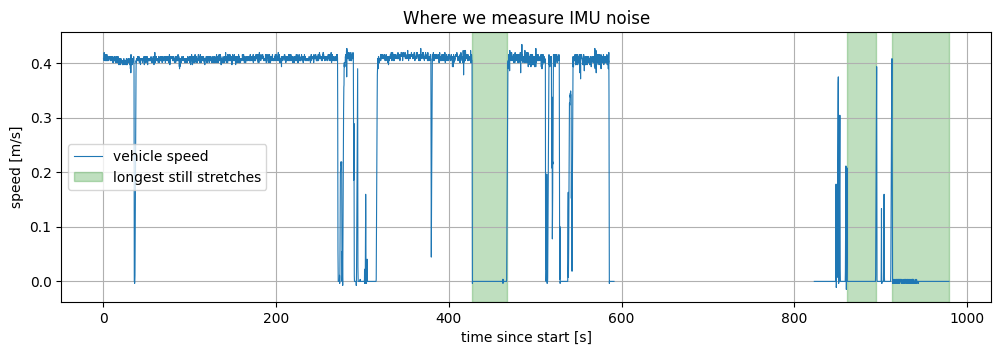

In [ ]:
# ---- Step 2a: find the moments when the vehicle was standing still ------------
# To measure the IMU's own noise we need data where the IMU is NOT really moving.
# The camera log has the vehicle speed, so we copy the nearest speed onto every IMU sample.
speed_at_imu = pd.merge_asof(
    imu[["t_ns"]],
    cam[["t_ns", "speed_mps"]],
    on="t_ns",
    direction="nearest",
    tolerance=300_000_000,   # only trust a speed reading within 0.3 s
)
imu["speed_mps"] = speed_at_imu["speed_mps"].values

STILL_SPEED = 0.02   # m/s: below this we call the vehicle "standing still"
SKIP_START_S = 30    # skip the first 30 s, where the IMU timestamps were glitchy

imu["is_still"] = (imu["speed_mps"] < STILL_SPEED) & (imu["t_s"] > SKIP_START_S)

# Group consecutive "still" samples into stretches. A new stretch starts whenever
# the vehicle starts/stops moving, or the IMU has a hole in its data (> 0.1 s).
new_stretch = (imu["is_still"] != imu["is_still"].shift()) | (imu["t_s"].diff() > 0.1)
imu["stretch_id"] = new_stretch.cumsum()

stretches = (
    imu[imu["is_still"]]
    .groupby("stretch_id")["t_s"]
    .agg(start_s="min", end_s="max", samples="size")
)
stretches["length_s"] = stretches["end_s"] - stretches["start_s"]
stretches = stretches.sort_values("length_s", ascending=False)

print("Longest standing-still stretches:")
print(stretches.head(5).round(1).to_string())

# Use the longest stretch for the noise measurements below.
# The speed reads 0 a moment before the vehicle has really settled, so we cut
# a few seconds off both ends to throw away leftover motion and vibration.
TRIM_S = 3
best = stretches.iloc[0]
still = imu[(imu["t_s"] >= best["start_s"] + TRIM_S) & (imu["t_s"] <= best["end_s"] - TRIM_S)]
print(f"\nUsing the longest one: {best['start_s'] + TRIM_S:.0f} s to {best['end_s'] - TRIM_S:.0f} s "
      f"({len(still) / 100:.0f} s, {len(still)} samples) after trimming {TRIM_S} s from each end")

# Plot: vehicle speed, with the three longest still stretches shaded green.
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(cam["t_s"], cam["speed_mps"], lw=0.8, label="vehicle speed")
for i, (_, s) in enumerate(stretches.head(3).iterrows()):
    ax.axvspan(s["start_s"], s["end_s"], color="green", alpha=0.25,
               label="longest still stretches" if i == 0 else None)
ax.set_xlabel("time since start [s]")
ax.set_ylabel("speed [m/s]")
ax.set_title("Where we measure IMU noise")
ax.legend()
plt.show()

### What this plot shows

The blue line is the vehicle speed. Green bands are the longest times the vehicle was parked while the IMU was recording. The table above the plot lists them: the longest is about 66 s at the very end of the recording (914 to 979 s), then ~40 s near 430 s and ~33 s near 860 s.

**What it means:** we use the longest one, after trimming 3 s from each end because the vehicle is still settling right after it stops. That leaves 60 s (5,968 samples) of a motionless IMU. Whatever wiggle remains in that data is the sensor's own noise.

IMU sample rate: 100.0 Hz

                       mean (bias)  std (noise)  density density unit
signal                                                               
angular_velocity_x        -0.00027      0.00224  0.00022    rad/s/√Hz
angular_velocity_y         0.00128      0.00246  0.00025    rad/s/√Hz
angular_velocity_z        -0.00009      0.00182  0.00018    rad/s/√Hz
linear_acceleration_x      0.19578      0.01980  0.00198     m/s²/√Hz
linear_acceleration_y      0.30085      0.02469  0.00247     m/s²/√Hz
linear_acceleration_z      9.78759      0.02898  0.00290     m/s²/√Hz

Length of the average accel vector: 9.794 m/s²  (true gravity: 9.81)


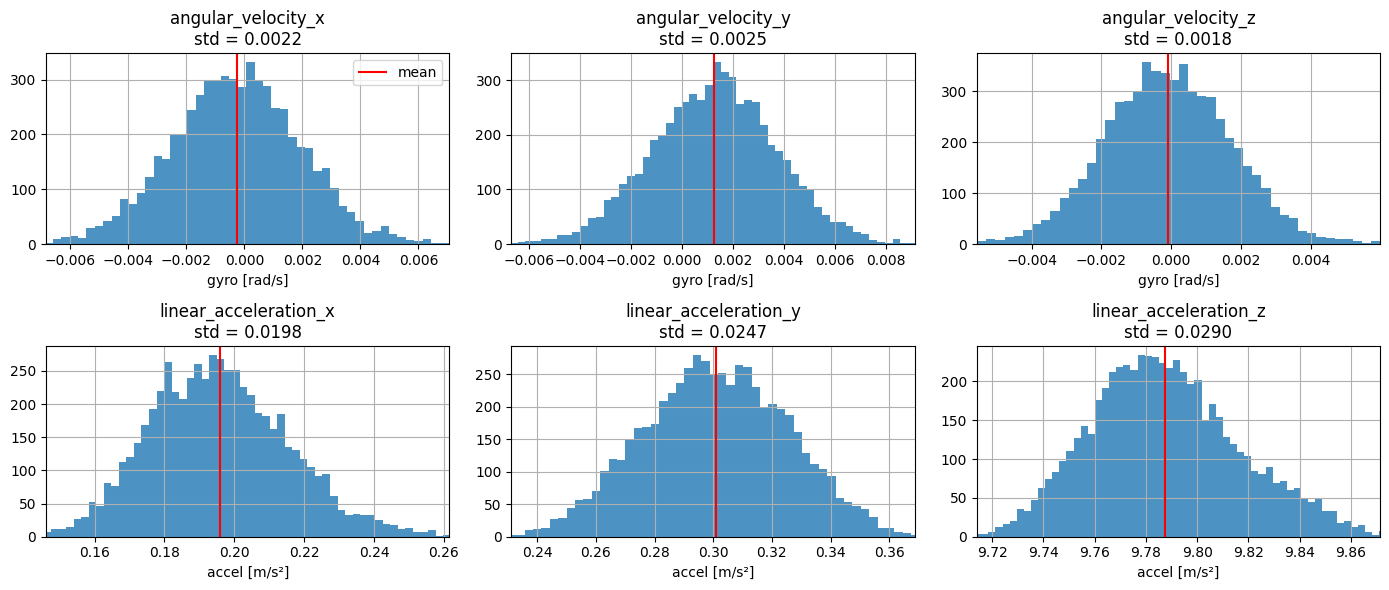

In [ ]:
# ---- Step 2b: how noisy is the IMU when it is standing still? --------------------
# On a perfectly still IMU every reading should be identical. What we see instead is
# the sensor's own noise. For each axis we compute:
#   mean      -> the constant offset ("bias"). Gyro should read 0 when not rotating.
#   std       -> the size of the random wiggle (noise), in the signal's own unit.
#   density   -> std / sqrt(sample rate). This is the standard number to compare IMUs,
#                because it does not depend on how fast the IMU is sampled.
SAMPLE_RATE_HZ = 1 / imu["t_s"].diff().median()   # about 100 Hz
print(f"IMU sample rate: {SAMPLE_RATE_HZ:.1f} Hz\n")

signals = {
    "gyro":  [f"angular_velocity_{a}" for a in "xyz"],      # rad/s
    "accel": [f"linear_acceleration_{a}" for a in "xyz"],   # m/s^2
}

rows = []
for sensor, columns in signals.items():
    for col in columns:
        values = still[col]
        rows.append({
            "signal": col,
            "mean (bias)": values.mean(),
            "std (noise)": values.std(),
            "density": values.std() / np.sqrt(SAMPLE_RATE_HZ),
        })
noise_table = pd.DataFrame(rows).set_index("signal")
noise_table["density unit"] = ["rad/s/√Hz"] * 3 + ["m/s²/√Hz"] * 3
print(noise_table.to_string(float_format=lambda v: f"{v:.5f}"))

# Gravity check: the accel vector should have length 9.81 m/s^2 when still.
g_measured = np.sqrt(sum(still[c].mean() ** 2 for c in signals["accel"]))
print(f"\nLength of the average accel vector: {g_measured:.3f} m/s²  (true gravity: 9.81)")

# Histograms: how the readings spread around their average.
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, col in zip(axes.flat, signals["gyro"] + signals["accel"]):
    ax.hist(still[col], bins=60, color="tab:blue", alpha=0.8)
    ax.set_xlim(still[col].quantile(0.001), still[col].quantile(0.999))  # hide rare extreme values
    ax.axvline(still[col].mean(), color="red", lw=1.5, label="mean")
    ax.set_title(f"{col}\nstd = {still[col].std():.4f}")
    ax.set_xlabel("gyro [rad/s]" if "angular" in col else "accel [m/s²]")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

### What the table and histograms show

Each histogram is the 60 s of still readings for one axis. The bell shape is what we want: the readings scatter randomly around an average (red line). Two numbers come out of each:

- **mean (bias):** where the bell is centered.
  - Gyro: should be 0 when not rotating. We get about 0.0003 rad/s on x, 0.0013 on y and 0.0001 on z. That is tiny (under 0.08 degrees per second), though it adds up if you integrate it over time.
  - Accel: the three axes together should give gravity (9.81 m/s²). We get 9.79, which is close. Gravity is not split perfectly onto z (x reads 0.20, y reads 0.30). That means the platform is tilted by a degree or two, or the accelerometer has a small offset.
- **std (noise):** how wide the bell is. About 0.002 rad/s for the gyro and 0.02 to 0.03 m/s² for the accelerometer.

The **density** column is std divided by √(sample rate). It lets you compare this IMU with the numbers in a datasheet, even if the datasheet's sample rate differs. We get roughly 0.0002 rad/s/√Hz for the gyro and 0.002 to 0.003 m/s²/√Hz for the accelerometer. Those are typical values for a small low-cost IMU.

**What it means:** the IMU itself is quiet and well behaved. It reads gravity correctly and its gyro bias is small.

Driving samples: 46118   Still samples (longest stretch): 5968
                       still std  driving std  driving / still
angular_velocity_x        0.0022       0.0457          20.4386
angular_velocity_y        0.0025       0.0516          20.9826
angular_velocity_z        0.0018       0.0605          33.2337
linear_acceleration_x     0.0198       0.7506          37.9048
linear_acceleration_y     0.0247       0.8570          34.7063
linear_acceleration_z     0.0290       1.4936          51.5379


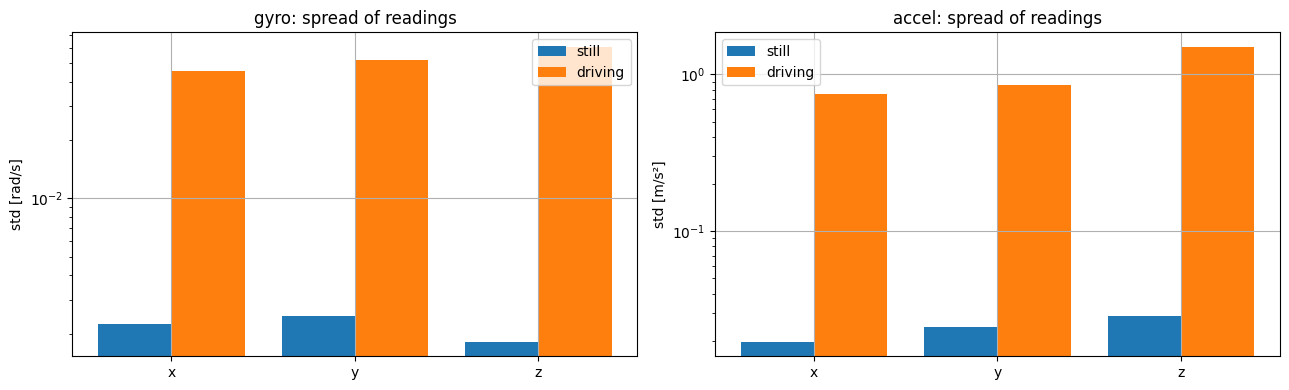

In [ ]:
# ---- Step 2c: still vs. driving -----------------------------------------------------
# Compare the size of the wiggle when still with the wiggle while driving.
# "std" below is just how spread out the readings are.
driving = imu[(imu["speed_mps"] > 0.3) & (imu["t_s"] > SKIP_START_S)]
print(f"Driving samples: {len(driving)}   Still samples (longest stretch): {len(still)}")

cols = signals["gyro"] + signals["accel"]
compare = pd.DataFrame({
    "still std":   [still[c].std() for c in cols],
    "driving std": [driving[c].std() for c in cols],
}, index=cols)
compare["driving / still"] = compare["driving std"] / compare["still std"]
print(compare.to_string(float_format=lambda v: f"{v:.4f}"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, sensor, unit in zip(axes, ["gyro", "accel"], ["rad/s", "m/s²"]):
    rows_ = compare.loc[signals[sensor]]
    x = np.arange(3)
    ax.bar(x - 0.2, rows_["still std"], width=0.4, label="still")
    ax.bar(x + 0.2, rows_["driving std"], width=0.4, label="driving")
    ax.set_xticks(x)
    ax.set_xticklabels(["x", "y", "z"])
    ax.set_yscale("log")   # log scale, because the difference is huge
    ax.set_ylabel(f"std [{unit}]")
    ax.set_title(f"{sensor}: spread of readings")
    ax.legend()
plt.tight_layout()
plt.show()

### What the bar chart shows

Blue bars are the wiggle size while still; orange bars are the wiggle size while driving. The vertical axis is logarithmic, so each gridline is 10 times bigger than the one below.

**What it means:** while driving, the readings spread out 20 to 50 times more than when parked. So almost everything we saw in the raw IMU plot while driving is real motion and vibration, and the sensor's own noise is small next to it. The IMU is not the weak link, but the vibration from driving is something a VIO system has to cope with.

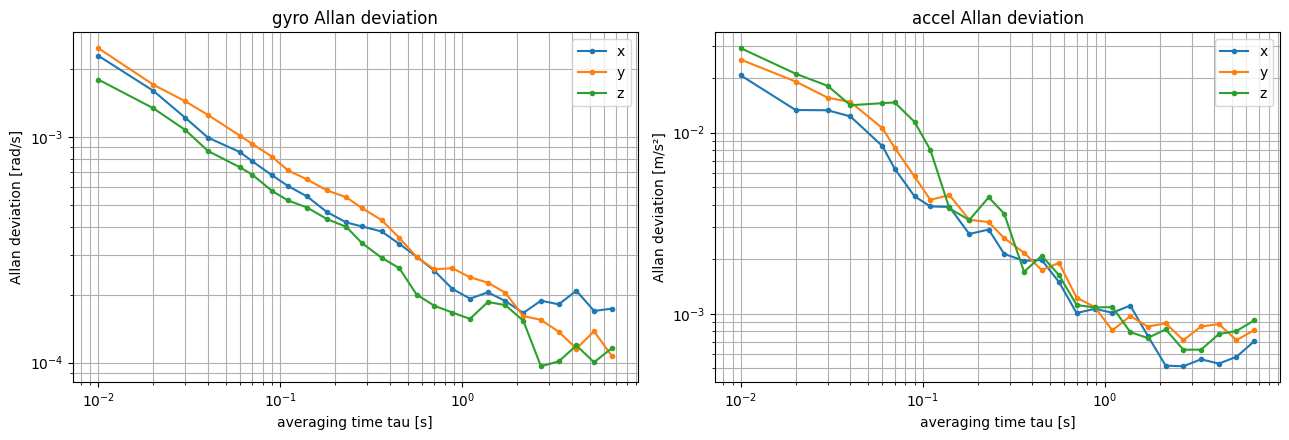

Allan deviation at tau = 1 s, and the lowest point of each curve:
  angular_velocity_x     at 1 s: 0.00020   lowest: 0.00017 at tau = 2.2 s
  angular_velocity_y     at 1 s: 0.00025   lowest: 0.00011 at tau = 6.6 s
  angular_velocity_z     at 1 s: 0.00016   lowest: 0.00010 at tau = 2.7 s
  linear_acceleration_x  at 1 s: 0.00104   lowest: 0.00051 at tau = 2.7 s
  linear_acceleration_y  at 1 s: 0.00094   lowest: 0.00072 at tau = 2.7 s
  linear_acceleration_z  at 1 s: 0.00109   lowest: 0.00063 at tau = 2.7 s


In [ ]:
# ---- Step 2d: Allan deviation ---------------------------------------------------------
# Idea: average the signal over windows of length tau, then see how much those averages
# differ from one window to the next.
#   * If the error is pure random noise, longer averaging makes the averages steadier,
#     so the curve goes DOWN (a straight line with slope -1/2 on a log-log plot).
#   * Eventually slow drift (the bias wandering) takes over and the curve flattens or
#     goes back UP. The lowest point is the best accuracy you can reach by averaging.
def allan_deviation(x, sample_rate, points=30):
    """Return (tau in seconds, Allan deviation) for the 1-D signal x."""
    n = len(x)
    # Window sizes (in samples), spread evenly on a log axis, at most n/9 so that
    # we always have at least 9 windows to compare.
    sizes = np.unique(np.logspace(0, np.log10(n // 9), points).astype(int))
    taus, devs = [], []
    for m in sizes:
        windows = n // m
        averages = x[: windows * m].reshape(windows, m).mean(axis=1)   # mean of each window
        diffs = np.diff(averages)                                       # change between neighbours
        devs.append(np.sqrt(0.5 * np.mean(diffs ** 2)))
        taus.append(m / sample_rate)
    return np.array(taus), np.array(devs)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
allan_results = {}
for ax, sensor, unit in zip(axes, ["gyro", "accel"], ["rad/s", "m/s²"]):
    for col in signals[sensor]:
        tau, dev = allan_deviation(still[col].values, SAMPLE_RATE_HZ)
        allan_results[col] = (tau, dev)
        ax.loglog(tau, dev, "o-", markersize=3, label=col[-1])
    ax.set_xlabel("averaging time tau [s]")
    ax.set_ylabel(f"Allan deviation [{unit}]")
    ax.set_title(f"{sensor} Allan deviation")
    ax.grid(True, which="both")
    ax.legend()
plt.tight_layout()
plt.show()

# Read the curve at tau = 1 s. For pure white noise this value equals the `density`
# computed earlier. If the two numbers disagree, the noise is not purely white
# (it has vibration or slow drift mixed in), and the Allan curve is the more honest one.
print("Allan deviation at tau = 1 s, and the lowest point of each curve:")
for col, (tau, dev) in allan_results.items():
    at_1s = np.interp(1.0, tau, dev)
    lowest = dev.argmin()
    print(f"  {col:22s} at 1 s: {at_1s:.5f}   lowest: {dev[lowest]:.5f} at tau = {tau[lowest]:.1f} s")

### What the Allan deviation plot shows

We average the signal over windows of length *tau* (horizontal axis) and ask how much neighbouring averages differ (vertical axis).

- **Falling line (left part):** random noise. Averaging for longer cancels it out, so the error drops. The steeper and lower the line, the better the sensor.
- **Flat or rising part (right part):** slow drift in the bias takes over, so more averaging no longer helps. The lowest point is the best accuracy you can get from averaging.

For this IMU the gyro curves fall until about 2 to 7 s and then flatten at roughly 0.0001 rad/s. The accelerometer curves flatten at about 0.0005 to 0.0007 m/s². The values at tau = 1 s, which are the usual "noise density" figures, are printed under the plot.

**Two cautions:**
- We only have 60 s of still data, so points beyond about 6 s are based on few windows and are rough. A proper bias-drift figure needs a recording of an hour or more.
- For the gyro, the Allan value at 1 s matches the `density` from the previous cell, so its noise is close to pure white noise. For the accelerometer the Allan value is about half the density, so some of its noise is fast vibration that averages out quickly.

**What it means:** these are the numbers to give a VIO or filtering tool as the IMU noise parameters (use the tau = 1 s values), as long as you remember they were measured on a short recording.

### Step 2 summary

| | Gyroscope | Accelerometer |
|---|---|---|
| Noise while still (std) | about 0.002 rad/s | about 0.02 to 0.03 m/s² |
| Noise density | about 0.0002 rad/s/√Hz | about 0.002 to 0.003 m/s²/√Hz |
| Offset (bias) | under 0.0013 rad/s | gravity reads 9.79 m/s² (true 9.81) |
| Noise while driving vs still | 20 to 33 times bigger | 35 to 50 times bigger |

These values are for this episode. They come from one 60 s still stretch, so treat them as estimates.

# IMU Noise